# From Whisper to Voice: System Walkthrough
*DyNaVoiCeR II: real-time whispered-to-speech conversion by per-pulse LPC filtering*

The system takes **whispered speech** and puts the voice back in. A whisper still carries the vocal-tract shape (the formants), but it has no glottal excitation. So we:

1. **estimate the vocal tract** of every frame from the whisper (LPC through ODFT, Wiener–Khinchin and Levinson–Durbin),
2. **synthesise a glottal source** (LF pulses following an $F_0$ contour, mixed with noise), and
3. **filter each pulse individually** with an envelope interpolated between frames, then overlap-add the results.

![System diagram](figures/systemDiagram.png)

| § | Block | Thesis |
|---|-------|--------|
| 1 | Glottal source: LF model, harmonic/NRD synthesis, $F_0$ contour | Ch. 4 |
| 2 | Vocal-tract filter: ODFT, Wiener–Khinchin, Levinson–Durbin, DF-II IIR, spectral tilt, vowel synthesis | Ch. 5 |
| 3 | Overlap-add engine: frame filtering vs. per-pulse filtering | Ch. 6.1 |
| 4 | Segmentation: whisper activity detection, centre of gravity, sigmoid mapping | Ch. 6.2–6.3 |
| 5 | Complete system: the MUSHRA test conditions side by side | Ch. 6.4, 7 |


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat, wavfile

import librosa as rosa

from IPython.display import Audio, display

# Global parameters (same as the STM32 implementation)
FS = 22050          # sampling frequency (Hz)
N = 1024            # analysis window = pulse buffer length
N2 = N // 2         # hop size = DMA buffer size (~23 ms)
NLPC = 22           # LPC filter order -> up to 11 formants
INT16_MAX = 32767

plt.rcParams.update(
    {'figure.figsize': (11, 3.5), 
     'font.size': 13,
     'axes.grid': True, 
     'grid.alpha': 0.3, 
     'figure.dpi': 110}
    )

def play(x, fs=FS, label=None, gain=1.0):
    """Peak-normalised audio player, with an optional label above it."""
    if label:
        print(label)
    display(Audio(gain * x / (np.max(np.abs(x)) + 1e-12), rate=fs, normalize=False))


def specshow(ax, x, fs=FS, fmax=8000, nfft=N, nperseg=N2):
    """Log-power spectrogram on a kHz axis."""
    f, t, S = signal.spectrogram(x, fs, window='hann', nperseg=nperseg,
                                 noverlap=3 * nperseg // 4, nfft=nfft)
    ax.pcolormesh(t, f / 1e3, 10 * np.log10(S + 1e-12), shading='auto', cmap='magma')
    ax.set_ylim(0, fmax / 1e3)
    ax.set_ylabel('Frequency (kHz)')
    ax.set_xlabel('Time (s)')
    ax.grid(False)

## 1 · Glottal source (Ch. 4)

### 1.1 The Liljencrants–Fant model

Voiced speech is excited by the **glottal flow derivative** (GFD). We use the LF model, ported from VOICEBOX `v_glotlf`, with its defaults $T_p = 0.48\,T_0$ and $T_e = 0.6\,T_0$:

$$
E(t) =
\begin{cases}
 E_0\, e^{a t} \sin(\omega_g t) & 0 \le t < T_e \quad \text{(open phase)}\\[2pt]
 -\dfrac{E_e}{\epsilon T_a}\left(e^{-\epsilon (t-T_e)} - e^{-\epsilon (T_0-T_e)}\right) & T_e \le t < T_0 \quad \text{(return phase)}
\end{cases}
$$

The sharp negative peak at $T_e$ (glottal closure) is what gives voiced speech its broadband energy.

### References

- [sap-voicebox](https://github.com/ImperialCollegeLondon/sap-voicebox) (Speech And Audio Processing Lab - Imperial College of London)

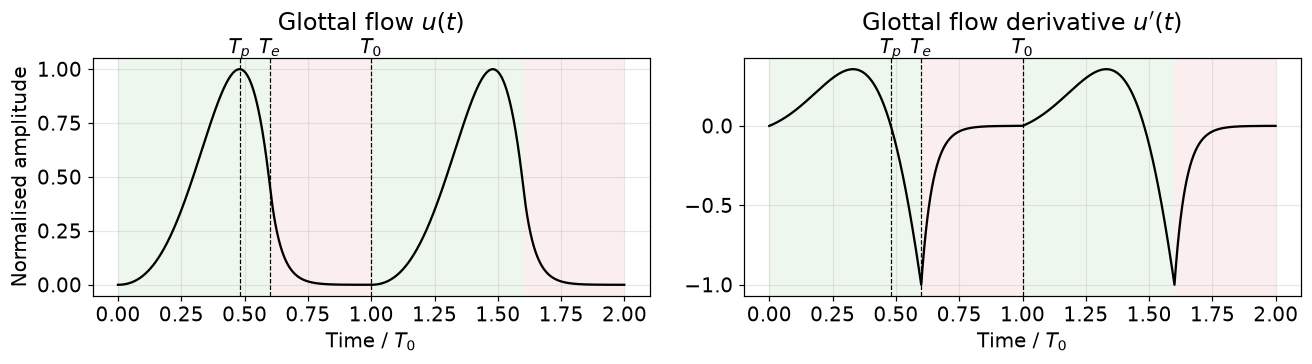

Raw LF pulse train @ 110 Hz (no vocal tract yet)


In [4]:
def v_glotlf(d=0, t=None, p=None):
    """LF glottal flow (d=0) or its derivatives (d=1, 2); t in periods. Port of VOICEBOX v_glotlf."""
    default_p = np.array([0.6, 0.1, 0.2])
    p = default_p if p is None else np.concatenate([p, default_p[len(p):]])
    tt = np.linspace(0, 0.99, 100) if t is None else t - np.floor(t)

    te = p[0]
    mtc = te - 1
    e0 = 1
    wa = np.pi / (te * (1 - p[2]))
    a = -np.log(-p[1] * np.sin(wa * te)) / te
    inta = e0 * ((wa / np.tan(wa * te) - a) / p[1] + wa) / (a**2 + wa**2)

    rb0 = p[1] * inta
    rb = rb0
    for _ in range(4):  # Newton iterations for the return-phase time constant
        kk = 1 - np.exp(mtc / rb)
        err = rb + mtc * (1 / kk - 1) - rb0
        derr = 1 - (1 - kk) * (mtc / rb / kk)**2
        rb = rb - err / derr

    e1 = 1 / (p[1] * (1 - np.exp(mtc / rb)))
    ta = tt < te
    tb = ~ta
    u = np.zeros_like(tt)
    if d == 0:
        u[ta] = e0 * (np.exp(a * tt[ta]) * (a * np.sin(wa * tt[ta]) - wa * np.cos(wa * tt[ta])) + wa) / (a**2 + wa**2)
        u[tb] = e1 * (np.exp(mtc / rb) * (tt[tb] - 1 - rb) + np.exp((te - tt[tb]) / rb) * rb)
    elif d == 1:
        u[ta] = e0 * np.exp(a * tt[ta]) * np.sin(wa * tt[ta])
        u[tb] = e1 * (np.exp(mtc / rb) - np.exp((te - tt[tb]) / rb))
    elif d == 2:
        u[ta] = e0 * np.exp(a * tt[ta]) * (a * np.sin(wa * tt[ta]) + wa * np.cos(wa * tt[ta]))
        u[tb] = e1 * np.exp((te - tt[tb]) / rb) / rb
    else:
        raise ValueError('Derivative must be 0, 1, or 2')
    return u


tt = np.linspace(0, 2, 2000, endpoint=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, d, name in zip(axs, (0, 1), ('Glottal flow $u(t)$', "Glottal flow derivative $u'(t)$")):
    u = v_glotlf(d, tt)
    ax.plot(tt, u / np.max(np.abs(u)), color='k')
    for k in range(2):
        ax.axvspan(k, k + 0.6, color='tab:green', alpha=0.08, lw=0)
        ax.axvspan(k + 0.6, k + 1, color='tab:red', alpha=0.08, lw=0)
    for x, lab in ((0.48, '$T_p$'), (0.6, '$T_e$'), (1.0, '$T_0$')):
        ax.axvline(x, ls='--', color='k', lw=0.8)
        ax.text(x, 1.02, lab, transform=ax.get_xaxis_transform(), ha='center')
    ax.set_xlabel('Time / $T_0$')
    ax.set_title(name, pad=18)
axs[0].set_ylabel('Normalised amplitude')
plt.tight_layout()
plt.show()

F0 = 110   # average fundamental frequency of male speech is around 110 Hz
GAIN = 0.4
buzz = v_glotlf(1, np.arange(FS) * F0 / FS)
play(buzz, label=f'Raw LF pulse train @ {F0} Hz (no vocal tract yet)', gain=GAIN)

### 1.3 Fundamental-frequency contour

A whisper carries no pitch, so prosody has to be *invented*. Following Ferreira (2016), every voiced stretch starts a stylised $F_0$ gesture: a short damped oscillation around the speaker's average $\hat F_0$ with a slow declination.

$$
F_0(t) = \phi\left[\hat F_0 (1-\alpha t)\, e^{-\beta t} \sin(\gamma t - 0.3\pi) - \theta t + \hat F_0\right]
$$

($\alpha = 0.13,\ \beta = 0.6,\ \gamma \approx \pi,\ \theta = 5$. The curve is shifted so that $F_0(0.5\,\text{s}) = \hat F_0$, as in `SegmentationF0`.) In the full system the contour restarts at every voiced onset and resets during unvoiced or silent frames. In the thesis we show that it is quite difficult to make the onset/reset voicing decision accurately.

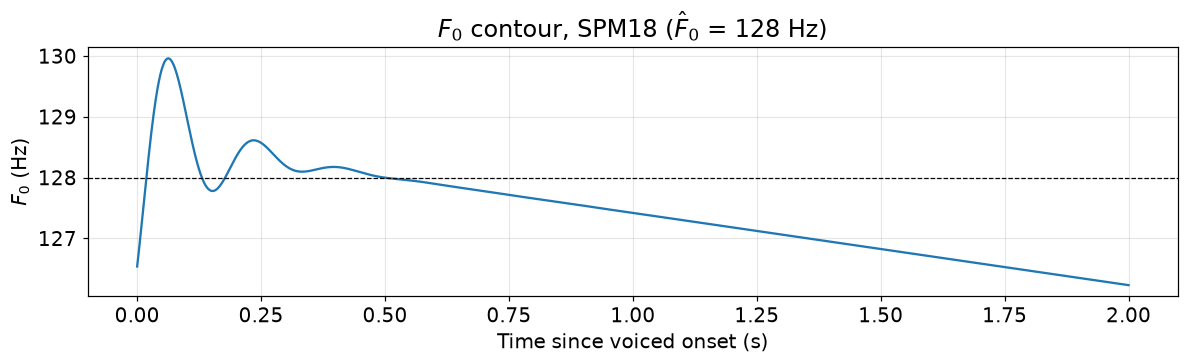

In [5]:
# Settings for test speaker SPM18 (Table 7.2)
F0_AVG = 128        # average F0 of the voiced reference (Hz)


def f0_contour(t, F0, alpha=0.13, beta=0.6, gamma=12 * 2 * np.pi / 25, theta=5, phi=0.02):
    """Stylised F0 gesture (Hz) for time t (s) after a voiced onset."""
    x_scale = N2**2 / FS    # the original code's frame-rate scaling of the time axis

    def shape(x):
        return F0 * (1 - alpha * x) * np.exp(-beta * x) * np.sin(gamma * x - 0.3 * np.pi) - theta * x + F0

    return (shape(t * x_scale) - shape(0.5 * x_scale)) * phi + F0


t_c = np.arange(int(2 * FS)) / FS
fig, ax = plt.subplots()
ax.plot(t_c, f0_contour(t_c, F0_AVG))
ax.axhline(F0_AVG, ls='--', color='k', lw=0.8)
ax.set(xlabel='Time since voiced onset (s)', ylabel='$F_0$ (Hz)',
       title=f'$F_0$ contour, SPM18 ($\\hat F_0$ = {F0_AVG} Hz)')
plt.tight_layout()
plt.show()

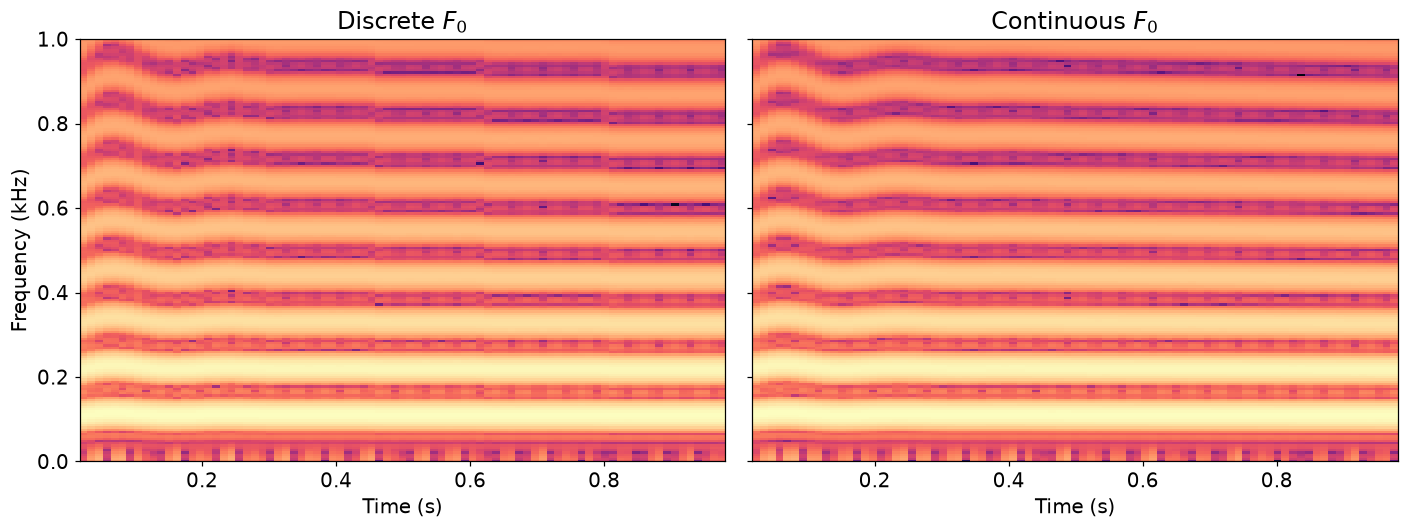

In [6]:
def pulse_train_discrete(contour, fs=FS):
    """Concatenate LF periods, each frozen at the F0 of its first sample."""
    out, pos = [], 0
    while pos < len(contour):
        f0 = contour[pos]
        tp = np.arange(0, 1 / f0, 1 / fs)
        out.append(v_glotlf(1, tp * f0))
        pos += len(tp)
    return np.concatenate(out)[:len(contour)]

def lf_pulse(f0, fs=FS, gain=None):
    """One period of the LF glottal flow derivative at f0 (Hz), sampled at fs.

    Length is ceil(fs / f0) samples, the same as the converter's pulses.
    If gain is set, the pulse is peak-normalised to that amplitude.
    """
    t = np.arange(0, 1 / f0, 1 / fs)    # time axis for one period (s)
    pulse = v_glotlf(1, t * f0)         # d=1 -> derivative; time given in fractions of a period
    if gain is not None:
        pulse = gain * pulse / np.max(np.abs(pulse))
    return pulse

def pulse_train_continuous(contour, fs=FS):
    """LF waveform driven by the integrated instantaneous F0 (phase in periods)."""
    return v_glotlf(1, np.cumsum(contour) / fs)


contour_250 = f0_contour(np.arange(FS) / FS, 110, phi=0.05)
trains = {'Discrete $F_0$': pulse_train_discrete(contour_250),
          'Continuous $F_0$': pulse_train_continuous(contour_250)}

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (name, x) in zip(axs, trains.items()):
    specshow(ax, x, fmax=1000, nfft=4 * N, nperseg=N)
    ax.set_title(name)
axs[1].set_ylabel('')
plt.tight_layout()
plt.show()

## 2 · Vocal-tract filter (Ch. 5)

The vocal tract is modelled as an all-pole filter $H(z) = b_0 / A(z)$ of order $p = 22$. Its coefficients are estimated **in the frequency domain**:

![LPC analysis chain](figures/lpcAnalysis.png)

We work from the PSD because every later step (tilt compensation, interpolating between frames, the centre of gravity) is a simple operation on it.

### 2.1 Odd-frequency DFT (ODFT)

The ODFT puts its bins at half-integer frequencies, $f_k = (k + \tfrac12)\,F_s/N$:

$$X_O[k] = \sum_{n=0}^{N-1} x[n]\,h[n]\,e^{-j\frac{2\pi}{N}(k+\frac12)n}, \qquad h[n] = \sin\!\left(\frac{\pi(n+\frac12)}{N}\right)$$

The **sine window** meets the Princen–Bradley condition $h^2[n] + h^2[n+N/2] = 1$. That makes 50 %-overlapped analysis and synthesis exact, which is why this window appears on both sides of the overlap-add.

> The reason for using the ODFT is that the regular DFT with frequency bins at integer multiples of 1/T (where T is the signal duration), given an inaccurate representation of the freq. spectrum near the top and bottom ends of the band.

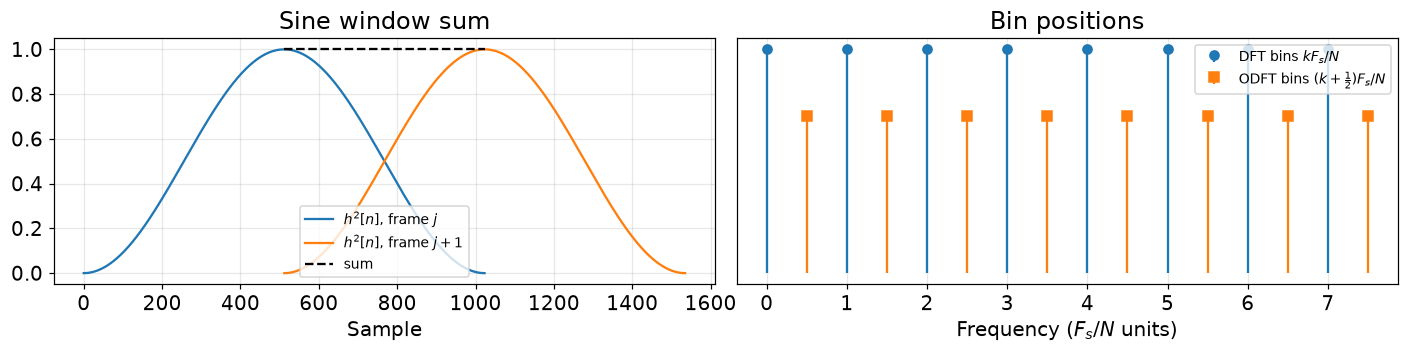

In [7]:
SINE_WIN = np.sin(np.pi * (np.arange(N) + 0.5) / N)


def odft(x, n=N):
    """Odd-frequency DFT: modulate by e^{-jπn/N}, then a standard FFT."""
    return np.fft.fft(x * np.exp(-1j * np.pi * np.arange(n) / n))


def iodft(X, n=N):
    """Inverse ODFT."""
    return np.fft.ifft(X) * np.exp(1j * np.pi * np.arange(n) / n)


x_test = np.random.default_rng(0).standard_normal(N)
assert np.allclose(iodft(odft(x_test)), x_test)                # perfect reconstruction
assert np.allclose(SINE_WIN[:N2]**2 + SINE_WIN[N2:]**2, 1.0)   # Princen–Bradley condition

# A real signal's ODFT is conjugate-symmetric about the middle: X[k] = X*[N-1-k].
# Every one-sided PSD in this notebook is mirrored with np.concatenate([P, P[::-1]]).
X_test = odft(x_test)
assert np.allclose(X_test, np.conj(X_test[::-1]))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
n = np.arange(N + N2)
axs[0].plot(n[:N], SINE_WIN**2, label='$h^2[n]$, frame $j$')
axs[0].plot(n[N2:], SINE_WIN**2, label='$h^2[n]$, frame $j+1$')
axs[0].plot(n[N2:N], SINE_WIN[N2:]**2 + SINE_WIN[:N2]**2, 'k--', label='sum')
axs[0].set(xlabel='Sample', title='Sine window sum')
axs[0].legend(fontsize=9, loc='lower center')

k = np.arange(8)
axs[1].stem(k, np.ones_like(k), linefmt='C0-', markerfmt='C0o', basefmt=' ', label='DFT bins $k F_s/N$')
axs[1].stem(k + 0.5, 0.7 * np.ones_like(k), linefmt='C1-', markerfmt='C1s', basefmt=' ', label='ODFT bins $(k+\\frac{1}{2}) F_s/N$')
axs[1].set(xlabel='Frequency ($F_s/N$ units)', yticks=[], title='Bin positions')
axs[1].legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

### 2.2 From PSD to filter: Wiener–Khinchin + Levinson–Durbin

**Wiener–Khinchin**: the autocorrelation is the inverse transform of the PSD, $r[\tau] = \mathcal{F}^{-1}\{|X_O[k]|^2\}$.

**Levinson–Durbin** then solves the Toeplitz (Yule–Walker) normal equations for $a_1 \dots a_p$ in $O(p^2)$ rather than $O(p^3)$. The final prediction error $E$ sets the gain, $b_0 = \sqrt{E}$ (autocorrelation matching).

We check the chain in two ways: against MATLAB's `levinson`, and by recovering a known resonator from noise it filtered.

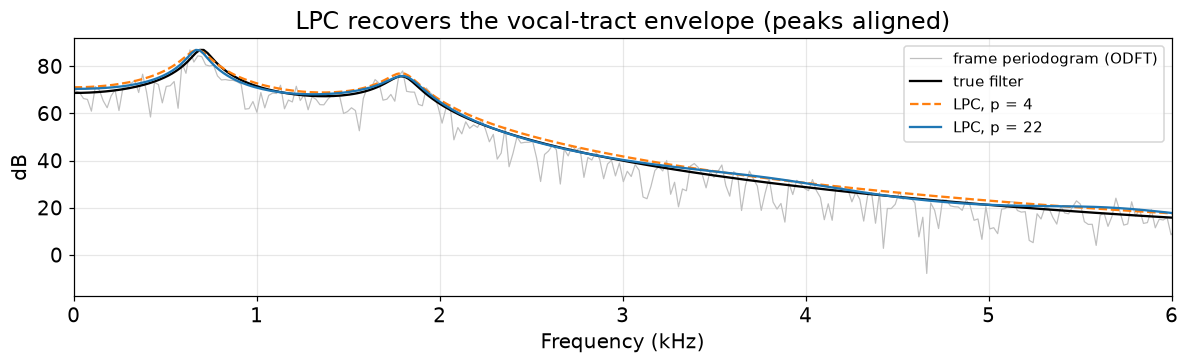

In [8]:
def levinson(r, p):
    """Levinson-Durbin recursion: autocorrelation r -> A(z) coefficients a, prediction error E, reflection coeffs k."""
    a = np.zeros(p + 1)
    a[0] = 1.0
    k = np.zeros(p)
    E = np.real(r[0])
    for i in range(1, p + 1):
        lam = -np.dot(r[1:i + 1], a[i - 1::-1]) / E
        a[1:i + 1] += lam * a[i - 1::-1]
        E *= 1.0 - lam**2
        k[i - 1] = -lam
    return a, E, k


def lpc_from_psd(psd, p=NLPC):
    """Full (mirrored) ODFT power spectrum -> all-pole filter (b0, a)."""
    r = iodft(psd).real                  # Wiener–Khinchin
    a, E, _ = levinson(r[:p + 1], p)
    return np.sqrt(E), a


def lpc_envelope_db(b0, a, n=N2):
    """Magnitude response of b0/A(z) in dB on n points up to Nyquist."""
    f, h = signal.freqz(b0, a, worN=n, fs=FS)
    return f, 20 * np.log10(np.abs(h) + 1e-12)


# DEBUG: check against against MATLAB's implementation: levinson([1 .7 0 .5 1 .5 0 .5 1], 6)
# a_ml = np.array([1.0, -0.158730158730140, -0.603174603174617, -0.158730158730125,
#                  -0.587301587301598, -0.317460317460331, 0.984126984126981])
# assert np.allclose(levinson(np.array([1.0, 0.7, 0, 0.5, 1.0, 0.5, 0.0, 0.5, 1.0]), 6)[0], a_ml)

# 2) Recover a known two-resonance filter from one windowed frame of the noise it shaped
rng = np.random.default_rng(1)
a_true = np.array([1.0])
for F, B in ((700, 100), (1800, 150)):
    r_pole = np.exp(-np.pi * B / FS)
    a_true = np.convolve(a_true, [1, -2 * r_pole * np.cos(2 * np.pi * F / FS), r_pole**2])
frame = signal.lfilter([1], a_true, rng.standard_normal(4 * N))[-N:]
psd_frame = np.abs(odft(frame * SINE_WIN))**2

fig, ax = plt.subplots()
f_bins = (np.arange(N2) + 0.5) * FS / N
ax.plot(f_bins / 1e3, 10 * np.log10(psd_frame[:N2]), color='0.75', lw=0.8, label='frame periodogram (ODFT)')
for (b0, a), name, style in (((1.0, a_true), 'true filter', 'k-'),
                             (lpc_from_psd(psd_frame, 4), 'LPC, p = 4', 'C1--'),
                             (lpc_from_psd(psd_frame, NLPC), f'LPC, p = {NLPC}', 'C0-')):
    f, env = lpc_envelope_db(b0, a)
    ax.plot(f / 1e3, env - env.max() + 10 * np.log10(psd_frame.max()), style, label=name)
ax.set(xlabel='Frequency (kHz)', ylabel='dB', xlim=(0, 6), title='LPC recovers the vocal-tract envelope (peaks aligned)')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

### 2.3 Spectral tilt compensation

The envelope we estimate from the whisper describes what the **output** should look like. The LF pulses already roll off towards high frequencies, though. Filtering them through that envelope as-is would apply the roll-off twice and muffle the result. So before computing the filter, we **divide the PSD by the pulse's spectral tilt**.

Following Ferreira, the tilt is approximated by three straight segments over log-frequency, relative to $f/F_0$:

$$
G(f) =
\begin{cases}
0\ \text{dB} & f/F_0 < 1 \\
m_1 \log_{10}(f/F_0) + b_1 & 1 \le f/F_0 < 2 \\
m_2 \log_{10}(f/F_0) + b_2 & f/F_0 \ge 2
\end{cases}
$$

Because $G$ depends on $F_0$, it is precomputed once for the speaker's average $\hat F_0$.

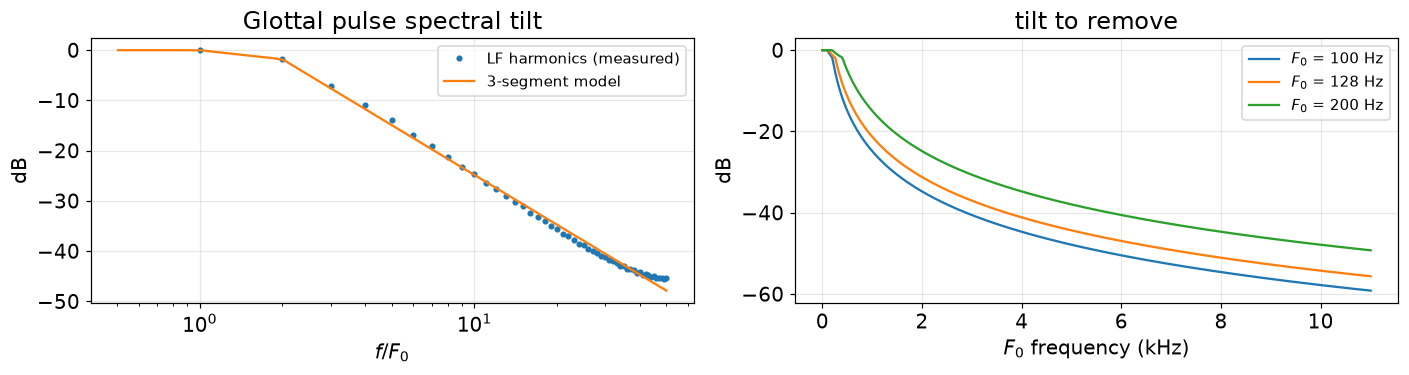

m1 = -5.97 dB/decade, m2 = -32.95 dB/decade


In [9]:
LF_MAG_DB = loadmat('LFmag.mat')['LFmag'][0]

# Fit the two sloped segments to the measured LF harmonic magnitudes (dB re. the fundamental)
lf_rel_db = LF_MAG_DB - LF_MAG_DB[0]
log_h = np.log10(np.arange(1, len(lf_rel_db) + 1))
m1, b1 = np.polyfit(log_h[:2], lf_rel_db[:2], 1)        # harmonics 1–2
m2, b2 = np.polyfit(log_h[1:48], lf_rel_db[1:48], 1)    # harmonics 2–48
b2 += (m1 * log_h[1] + b1) - (m2 * log_h[1] + b2)       # join the segments at the 2nd harmonic


def tilt_gain(f0, n=N, fs=FS):
    """Linear LF tilt magnitude on the n-point grid, mirrored like an ODFT spectrum."""
    ratio = np.arange(n // 2) * fs / (f0 * n)
    with np.errstate(divide='ignore'):
        g_db = np.piecewise(ratio, [ratio < 1, (ratio >= 1) & (ratio < 2), ratio >=2],
            [lambda x: 0.0, 
             lambda ratio: m1 * np.log10(ratio) + b1, 
             lambda ratio: m2 * np.log10(ratio) + b2])
    g = 10**(g_db / 20)
    return np.concatenate([g, g[::-1]])


fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
ratio = np.arange(N2) * FS / (F0_AVG * N)
keep = (ratio >= 0.5) & (ratio <= len(lf_rel_db))
axs[0].semilogx(np.arange(1, len(lf_rel_db) + 1), lf_rel_db, 'o', ms=3, label='LF harmonics (measured)')
axs[0].semilogx(ratio[keep], 20 * np.log10(tilt_gain(F0_AVG)[:N2][keep]), 'C1', label='3-segment model')
axs[0].set(xlabel='$f / F_0$', ylabel='dB', title='Glottal pulse spectral tilt')
axs[0].legend(fontsize=10)

f_axis = np.arange(N2) * FS / N
for f0 in (100, F0_AVG, 200):
    axs[1].plot(f_axis / 1e3, 20 * np.log10(tilt_gain(f0)[:N2]), label=f'$F_0$ = {f0} Hz')
axs[1].set(xlabel='$F_0$ frequency (kHz)', ylabel='dB', title='tilt to remove')
axs[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f'm1 = {m1:.2f} dB/decade, m2 = {m2:.2f} dB/decade')

### 2.4 Putting the source and the filter together: vowel synthesis

Before tackling whispers, we validate source + filter on their own. For this I have recorded voiced speech samples for each the portuguese tonic vowel: /a/, /e/, /i/, /o/ /u/

We can use this to derive a filter which may then be used to synthesize:

- Voiced vowels, if excited with the LF pulses
- Whispered vowels, if excited using white noise. 

<!-- 1. subtract the LF tilt at $F_0 = 250$ Hz,
2. turn the envelope into a filter with IODFT and Levinson ($p = 22$),
3. excite it with an LF pulse train that follows the $F_0$ contour. -->


Average f0: 110.96559889042987
Original sample


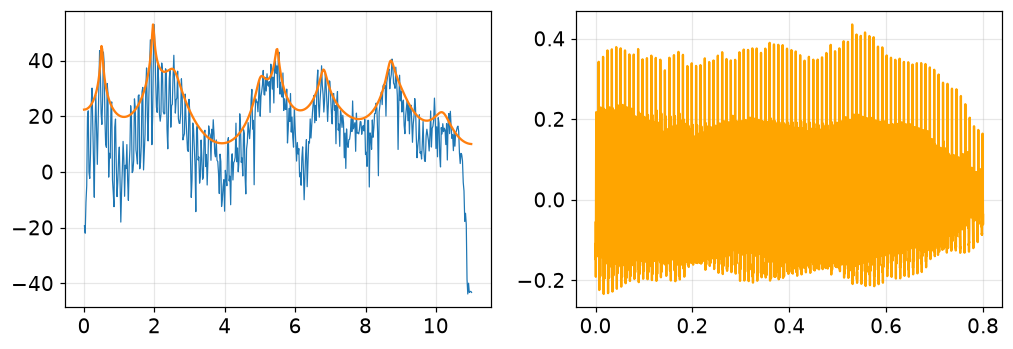

In [10]:
from pathlib import Path

DATA_DIR = Path('data')
VOWEL = 'e'

# load the sample
rec, _ = rosa.load(DATA_DIR / f'vowel_test/vowel_{VOWEL}.wav', sr=FS, offset=0.2, duration=0.8)
t = np.arange(len(rec))/FS

# fundamental frequency estimation
f0, voiced_flag, voiced_provs = rosa.pyin(rec, sr=FS, fmin = 50, fmax = 200)
F0 = np.average(f0)
print(f'Average f0: {F0}')

# Generate a filter from the first N samples
frame = rec[1*N:2*N]
psd_frame = np.abs(odft(frame * SINE_WIN))**2
psd_frame = psd_frame / (tilt_gain(F0)**2)

# lpc synth
b0, a = lpc_from_psd(psd_frame, NLPC)
f, env = lpc_envelope_db(b0, a)

fig, ax = plt.subplots(1,2)
f_bins = (np.arange(N2) + 0.5) * FS / N
ax[0].plot(f_bins / 1e3, 10 * np.log10(psd_frame[:N2]), lw=0.8, label='frame periodogram (ODFT)')
ax[1].plot(t, rec, label='signal', color='orange')
ax[0].plot(f /1e3, env - env.max() + 10 * np.log10(psd_frame.max()))


play(rec, FS, label="Original sample")

In [11]:
FADE = 0.02
DUR = 1.0

pulses = pulse_train_continuous(f0_contour(np.arange(int(DUR * FS)) / FS, F0, phi=0.06))
noise = np.random.normal(0, 0.1, int(DUR*FS))   # fixed noise template, reused by every pulse

synth_voice = signal.lfilter([b0], a, pulses)
synth_whisper = signal.lfilter([b0], a, noise)

ramp = np.linspace(0, 1, int(FADE * FS))
synth_voice[:len(ramp)] *= ramp
synth_voice[-len(ramp):] *= ramp[::-1]
synth_whisper[:len(ramp)] *= ramp
synth_whisper[-len(ramp):] *= ramp[::-1]

play(synth_voice, label = f'Synthesized /{VOWEL}/ vowel ')
play(synth_whisper, label = f'Synthesized /{VOWEL}/ whispered vowel ')

Synthesized /e/ vowel 


Synthesized /e/ whispered vowel 


## 3 · Overlap-add engine (Ch. 6.1)

Now the filter comes from the whisper conversion itself:

- Every 512 new input samples, the window `[previous | current]` (1024 samples, sine-windowed) gives a new PSD $P_j$.
- A 1024-sample **pulse buffer** shifts by 512. New pulses are generated wherever the previous pulse ended (`lastPulsePos`) until that position passes 512.
- Each pulse is filtered and **added** into the buffer, ring-out included, so neighbouring pulses overlap. The first 512 samples are then output.

Two ways to filter the pulses of one block:

| | filter | sounds like |
|---|---|---|
| **Frame filtering** | one $H_j(z)$ from $P_j$ for every pulse in the block | an electrolarynx: the envelope jumps every 23 ms |
| **Pulse filtering** | pulse $k$ gets $H_k(z)$ from $(1-\alpha_k)P_{j-1} + \alpha_k P_j$, with $\alpha_k = \text{pos}_k / 512$ | envelope glides smoothly from pulse to pulse |

![Per-pulse filtering](figures/pulseMap.png)

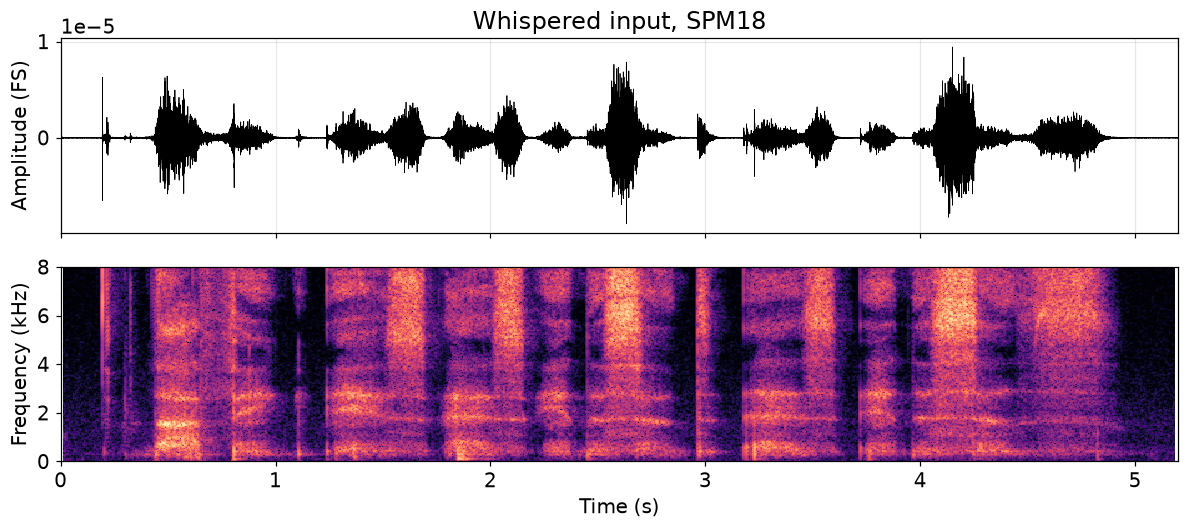

Whispered input


Voiced reference


In [12]:
WHISPER_FILE = DATA_DIR / 'nothing_whispered.wav'   # "Nothing is as innocent as innocence"
VOICED_FILE = DATA_DIR / 'nothing_voiced.wav'


whisper, _ = rosa.load(WHISPER_FILE, sr=FS, offset = 0.2, duration=5.2)
t_in = np.arange(len(whisper)) / FS

fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axs[0].plot(t_in, whisper / INT16_MAX, lw=0.5, color='k')
axs[0].set(ylabel='Amplitude (FS)', title='Whispered input, SPM18', xlim=(0, t_in[-1]))
specshow(axs[1], whisper)
plt.tight_layout()
plt.show()

play(whisper, label='Whispered input')

voiced, _ = rosa.load(VOICED_FILE, sr=FS)
play(voiced, label='Voiced reference')

In [13]:
F0_MIN = 50          # lowest F0 the pulse buffer is sized for (Hz)
PULSE_TAIL = 300     # samples of filter ring-out kept after each pulse
PSD_FLOOR = 1e-6     # keeps Levinson finite on digitally silent frames

F_VUV = 2000        # CoG below this -> vocalic (Hz)
F_UV = 3000         # CoG above this -> unvoiced (Hz)

F0_AVG = 110

def analysis_frames(x):
    """Yield (frame index, 512 new samples, ODFT power spectrum of the sine-windowed [prev | new])."""
    old = np.zeros(N2)
    for j, start in enumerate(range(0, len(x) - N2, N2)):
        new = x[start:start + N2]
        yield j, new, np.abs(odft(np.concatenate([old, new]) * SINE_WIN))**2 + PSD_FLOOR
        old = new


def convert(x, f0=F0_AVG, mode='pulse', segmentation=False, contour=False,
            f_vuv=F_VUV, f_uv=F_UV, noise_gain=0.2, legacy_output_window=False, seed=0):
    """Whisper -> voiced speech, block by block as on the STM32.

    mode          'frame': one LPC filter per block; 'pulse': one filter per pulse from the interpolated PSD
    segmentation  WAD activity + centre-of-gravity voicing (wad / cog_mapping are defined in §4)
    contour       F0 follows f0_contour, restarting at each voiced onset; otherwise constant f0
    legacy_output_window  re-apply the sine window to consecutive output blocks, as overlapAdd.ipynb did
    """
    tilt = tilt_gain(f0)
    buf = np.zeros(max(N, N2 + int(np.ceil(FS / F0_MIN)) + PULSE_TAIL))
    old_psd, old_out = np.zeros(N), np.zeros(N2)
    pos, onset = 1, 0        # pos starts at 1 so alpha > 0 against the all-zero first PSD
    out = []
    trace = dict(cog=[], beta=[], activity=[], pulses=[])

    for j, new, psd in analysis_frames(x):
        beta, activity = 0.0, 1.0
        if segmentation:
            cog = centre_of_gravity(psd)
            beta, activity = cog_mapping(cog, f_vuv, f_uv), wad(new)
            trace['cog'].append(cog)
        trace['beta'].append(beta)
        trace['activity'].append(activity)

        # NB: as in the thesis code, the PSD (power) is divided by the tilt *magnitude*
        if mode == 'frame':
            b0, a = lpc_from_psd(psd / (tilt**2))

        buf[:-N2] = buf[N2:]     # advance the pulse buffer by one block
        buf[-N2:] = 0
        while pos < N2:
            if contour:
                f_start = f0_contour(onset / FS, f0)
                tp = np.arange(0, 1 / f_start, 1 / FS)
                pulse = v_glotlf(1, tp * f0_contour((onset + np.arange(len(tp))) / FS, f0))
                noise = np.random.normal(0, 0.1, N)   # fixed noise template, reused by every pulse
                onset += int(FS / f_start)
            else:
                pulse = lf_pulse(f0)

            if segmentation:
                mix = 0.5 * beta + 0.5            # keeps some noise even in fully voiced frames
                pulse = (pulse * (1 - mix) + noise_gain * noise[:len(pulse)] * mix) * activity

            alpha = pos / N2
            if mode == 'pulse':
                b0, a = lpc_from_psd((alpha * psd + (1 - alpha) * old_psd) / (tilt**2))

            y = signal.lfilter([b0], a, np.r_[pulse, np.zeros(PULSE_TAIL)])
            buf[pos:pos + len(y)] += y
            trace['pulses'].append((j, pos, alpha))
            pos += len(pulse)

        pos -= N2
        if contour and (beta > 0.5 or activity < 0.5):
            onset = 0                             # restart the F0 gesture at the next voiced onset
        old_psd = psd

        block = buf[:N2].copy()
        out.append(old_out * SINE_WIN[:N2] + block * SINE_WIN[N2:] if legacy_output_window else block)
        old_out = block

    return np.concatenate(out), {k: np.array(v) for k, v in trace.items()}

### 3.1 Inside one block

We run both variants over the whole recording, then zoom in on a single block $j$ (by default the loudest one). The left panel shows the envelope each pulse is filtered with: it slides from $P_{j-1}$ towards $P_j$ as $\alpha_k$ grows. The right panel shows the resulting 512 output samples.

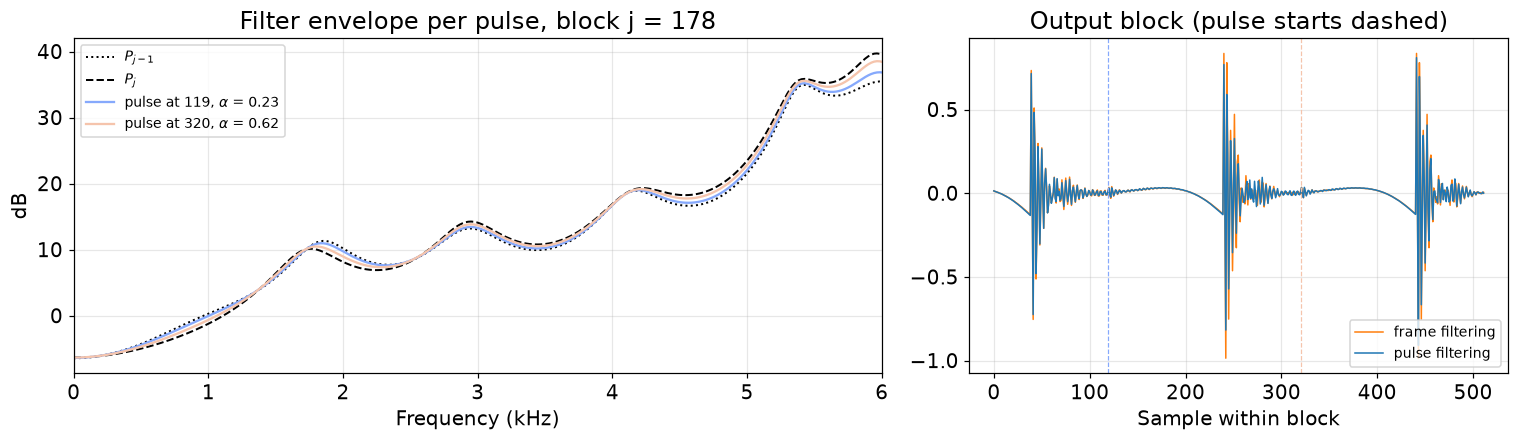

In [14]:
y_frame, tr_frame = convert(whisper, mode='frame')
y_pulse, tr_pulse = convert(whisper, mode='pulse')

psds = [P for _, _, P in analysis_frames(whisper)]
J = int(np.argmax([P[:N2].sum() for P in psds]))     # loudest block; set by hand to inspect others
pulses_J = tr_pulse['pulses'][tr_pulse['pulses'][:, 0] == J]
tilt = tilt_gain(F0_AVG)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [3, 2]})
for P, ls, name in ((psds[J - 1], ':', '$P_{j-1}$'), (psds[J], '--', '$P_j$')):
    f, env = lpc_envelope_db(*lpc_from_psd(P / tilt))
    axs[0].plot(f / 1e3, env, color='k', ls=ls, lw=1.3, label=name)
for _, pos, alpha in pulses_J:
    f, env = lpc_envelope_db(*lpc_from_psd((alpha * psds[J] + (1 - alpha) * psds[J - 1]) / tilt))
    axs[0].plot(f / 1e3, env, color=plt.cm.coolwarm(alpha), label=f'pulse at {int(pos)}, $\\alpha$ = {alpha:.2f}')
axs[0].set(xlabel='Frequency (kHz)', ylabel='dB', xlim=(0, 6), title=f'Filter envelope per pulse, block j = {J}')
axs[0].legend(fontsize=9)

n_blk = np.arange(J * N2, (J + 1) * N2)
axs[1].plot(n_blk - J * N2, y_frame[n_blk] / np.max(np.abs(y_frame)), color='tab:orange', lw=1, label='frame filtering')
axs[1].plot(n_blk - J * N2, y_pulse[n_blk] / np.max(np.abs(y_pulse)), color='tab:blue', lw=1, label='pulse filtering')
for _, pos, alpha in pulses_J:
    axs[1].axvline(pos, color=plt.cm.coolwarm(alpha), ls='--', lw=0.8)
axs[1].set(xlabel='Sample within block', title='Output block (pulse starts dashed)')
axs[1].legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

### 3.2 Frame filtering vs. pulse filtering

Both are still "fully voiced": every frame is excited by pulses at a constant $\hat F_0$, even fricatives and pauses. That is the problem §4 solves. Listen for the 23 ms "steps" in frame filtering.

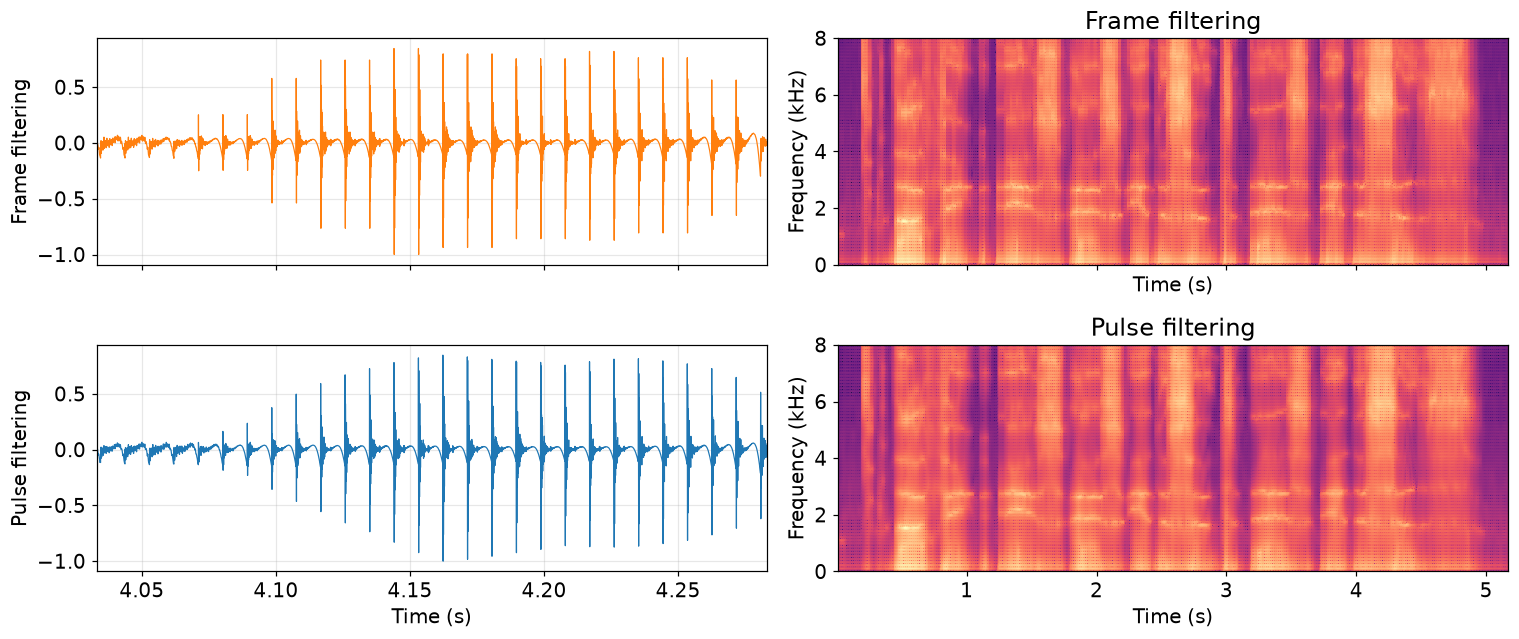

Whispered


Frame filtering


Pulse filtering


In [15]:
t0 = max(0.0, J * N2 / FS - 0.1)           # 250 ms around the inspected block
zoom = slice(int(t0 * FS), int((t0 + 0.25) * FS))
t_zoom = np.arange(zoom.start, zoom.stop) / FS

fig, axs = plt.subplots(2, 2, figsize=(14, 6), sharex='col')
for row, (name, synth_voice, color) in enumerate((('Frame filtering', y_frame, 'tab:orange'),
                                        ('Pulse filtering', y_pulse, 'tab:blue'))):
    axs[row, 0].plot(t_zoom, synth_voice[zoom] / np.max(np.abs(synth_voice[zoom])), color=color, lw=0.8)
    axs[row, 0].set(ylabel=name, xlim=(t_zoom[0], t_zoom[-1]))
    specshow(axs[row, 1], synth_voice)
    axs[row, 1].set_title(name)
axs[1, 0].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

play(whisper, label='Whispered')
play(y_frame, label='Frame filtering')
play(y_pulse, label='Pulse filtering')

## 4 · Segmentation (Ch. 6.2–6.3)

Voicing every frame is wrong in two ways: **pauses** become buzz, and **unvoiced consonants** (/s/, /ʃ/, /f/…) become vowels. Two cheap per-frame features fix that.

### 4.1 Whisper activity detection (WAD)

A modified G.729 VAD looks at each block's energy $E$ and zero-crossing rate $\gamma$:

$$
\text{activity} =
\begin{cases}
1 & E \ge \zeta_2 \\
0 & E < \zeta_1 \\
\tfrac12\left(\operatorname{sign}(\gamma - \zeta_{zcr}) + 1\right) & \text{otherwise}
\end{cases}
$$

The thresholds were tuned by hand for each speaker. Silent blocks mute the excitation, and they also reset the $F_0$ contour.

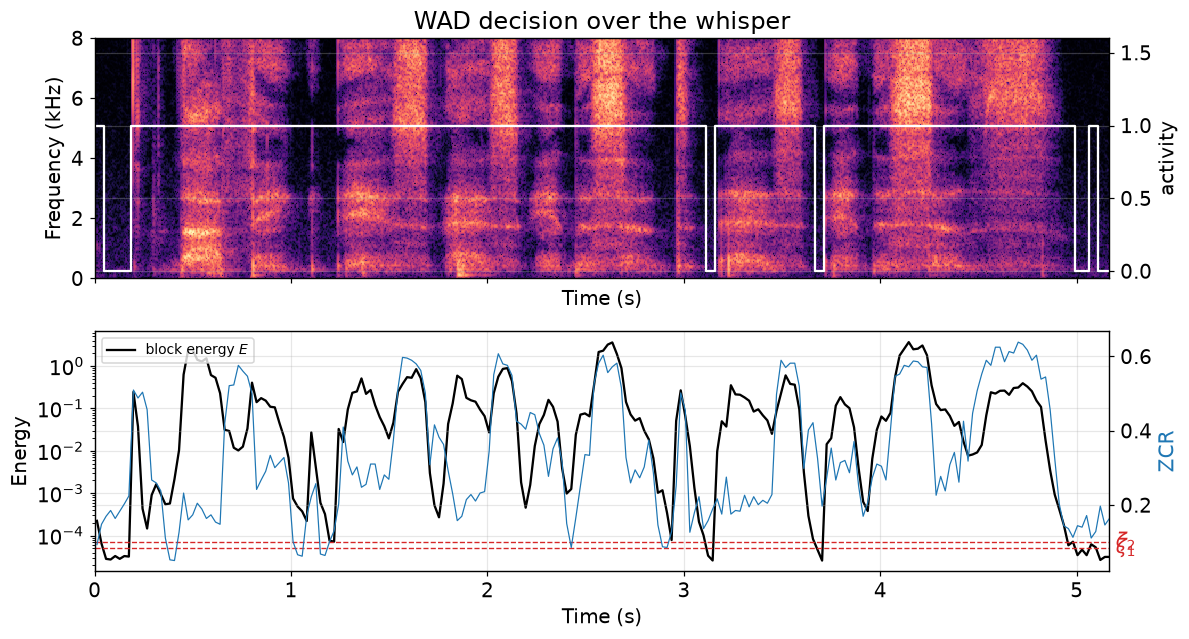

In [16]:
WAD_Z1 = 0.5e-4   # below: silence  (block energy, int16 scale, 512 samples)
WAD_Z2 = 0.7e-4    # above: speech
WAD_ZCR = 0.1       # zero-crossing threshold for the grey zone


def zero_crossing_rate(frame):
    return np.sum(frame[:-1] * frame[1:] < 0) / len(frame)


def wad(frame, z1=WAD_Z1, z2=WAD_Z2, z_zcr=WAD_ZCR):
    """Modified G.729 whisper activity detection on the 512 new samples of a block."""
    energy = np.sum(frame**2)
    if energy >= z2:
        return 1.0
    if energy < z1:
        return 0.0
    return 0.5 * np.sign(zero_crossing_rate(frame) - z_zcr) + 0.5


blocks = [new for _, new, _ in analysis_frames(whisper)]
t_blk = (np.arange(len(blocks)) + 0.5) * N2 / FS
energy = np.array([np.sum(b**2) for b in blocks])
zcr = np.array([zero_crossing_rate(b) for b in blocks])
activity = np.array([wad(b) for b in blocks])

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
specshow(axs[0], whisper)
ax_r = axs[0].twinx()
ax_r.step(t_blk, activity, where='mid', color='w', lw=1.5)
ax_r.set(ylim=(-0.05, 1.6), ylabel='activity')
axs[0].set_title('WAD decision over the whisper')

axs[1].semilogy(t_blk, energy, color='k', label='block energy $E$')
for z, name in ((WAD_Z1, r'$\zeta_1$'), (WAD_Z2, r'$\zeta_2$')):
    axs[1].axhline(z, ls='--', color='tab:red', lw=0.9)
    axs[1].text(t_blk[-1], z, ' ' + name, va='center', color='tab:red')
ax_z = axs[1].twinx()
ax_z.plot(t_blk, zcr, color='tab:blue', lw=0.8)
ax_z.set_ylabel('ZCR', color='tab:blue')
axs[1].set(xlabel='Time (s)', ylabel='Energy', xlim=(0, t_blk[-1]))
axs[1].legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

### 4.2 Voicing decisions from the spectral centre of gravity

In whispered **vowels** the energy sits around the formants (low). In **fricatives** it sits high. The spectral centre of gravity (Perrotin et al.) captures this in a single number per block:

$$
\text{CoG} = \frac{\sum_{k=0}^{N/2} f_k\, P[k]}{\sum_{k=0}^{N/2} P[k]}
$$

A sigmoid maps it to the **voicing coefficient** $\beta \in [0, 1]$ (0 = vocalic, 1 = unvoiced). The curve is centred on $\sqrt{F_{vuv}F_{uv}}$, and its steepness is set by $\tau$, the fraction of the $[F_{vuv}, F_{uv}]$ range that the transition fills:

$$
\beta = \sigma(\text{CoG}) = \frac{1}{1 + e^{-\lambda(\text{CoG} - \sqrt{F_{vuv}F_{uv}})}}, \qquad
\lambda = \frac{2}{F_{uv} - F_{vuv}} \ln\frac{1+\tau}{1-\tau}
$$

For SPM18, $F_{vuv} = 1.8$ kHz and $F_{uv} = 2.4$ kHz.

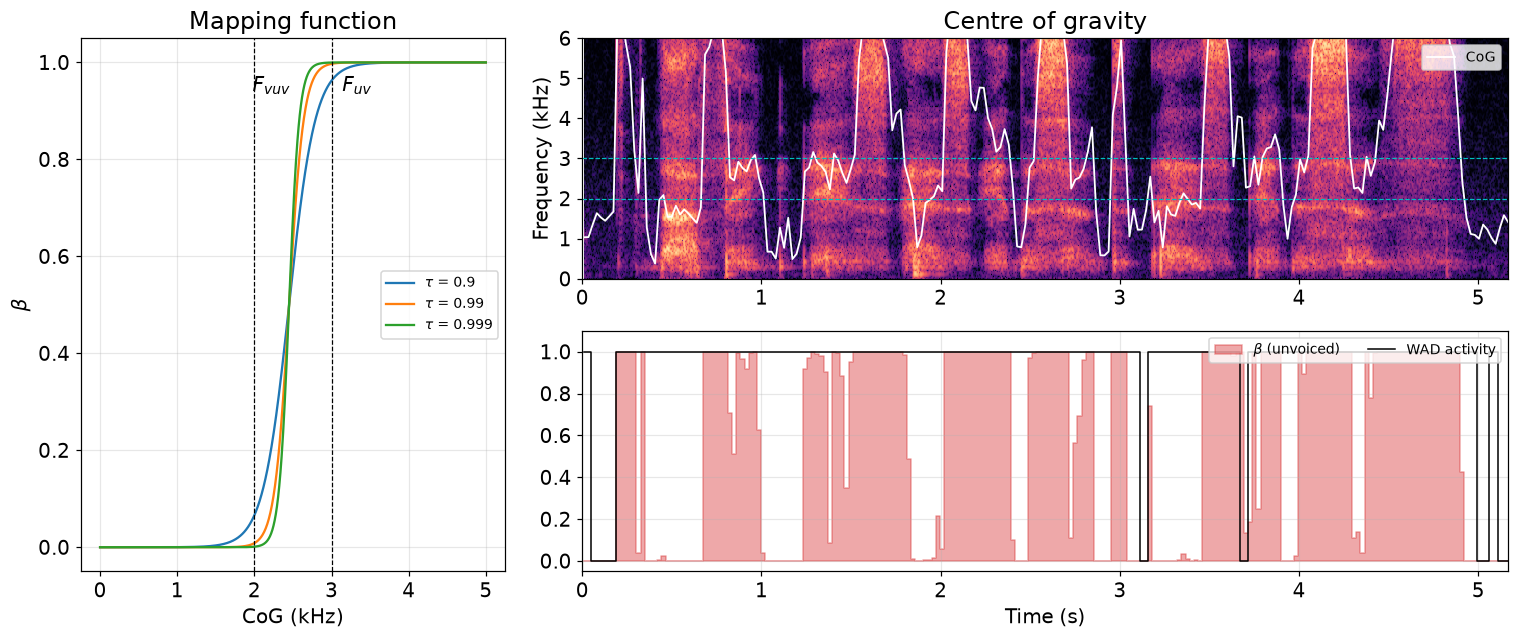

In [17]:
def centre_of_gravity(psd, fs=FS):
    """Power-weighted mean frequency (Hz) of the one-sided spectrum."""
    n = len(psd)
    f = np.arange(n // 2) * fs / n
    return np.sum(f * psd[:n // 2]) / np.sum(psd[:n // 2])


def cog_mapping(cog, f_vuv=F_VUV, f_uv=F_UV, tau=0.99):
    """Sigmoid CoG -> voicing coefficient beta (0 = vocalic, 1 = unvoiced)."""
    lam = 2 / (f_uv - f_vuv) * np.log((1 + tau) / (1 - tau))
    return 1 / (1 + np.exp(-lam * (cog - np.sqrt(f_vuv * f_uv))))


cog = np.array([centre_of_gravity(P) for _, _, P in analysis_frames(whisper)])
beta = cog_mapping(cog)

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3)
ax_sig = fig.add_subplot(gs[:, 0])
f_sweep = np.linspace(0, 5000, 1000)
for tau in (0.9, 0.99, 0.999):
    ax_sig.plot(f_sweep / 1e3, cog_mapping(f_sweep, tau=tau), label=f'$\\tau$ = {tau}')
for f_th, name in ((F_VUV, '$F_{vuv}$'), (F_UV, '$F_{uv}$')):
    ax_sig.axvline(f_th / 1e3, ls='--', color='k', lw=0.8)
    ax_sig.text(f_th / 0.9e3, 0.9, name, ha='center', transform=ax_sig.get_xaxis_transform())
ax_sig.set(xlabel='CoG (kHz)', ylabel=r'$\beta$', title='Mapping function', ylim=(-0.05, 1.05))
ax_sig.legend(fontsize=9, loc='center right')

ax_spec = fig.add_subplot(gs[0, 1:])
specshow(ax_spec, whisper, fmax=6000)
ax_spec.plot(t_blk, cog / 1e3, color='w', lw=1.2, label='CoG')
for f_th in (F_VUV, F_UV):
    ax_spec.axhline(f_th / 1e3, ls='--', color='c', lw=0.8)
ax_spec.set(title='Centre of gravity', xlabel='')
ax_spec.legend(fontsize=9, loc='upper right')

ax_b = fig.add_subplot(gs[1, 1:], sharex=ax_spec)
ax_b.fill_between(t_blk, beta, step='mid', color='tab:red', alpha=0.4, label=r'$\beta$ (unvoiced)')
ax_b.step(t_blk, activity, where='mid', color='k', lw=1, label='WAD activity')
ax_b.set(xlabel='Time (s)', ylim=(-0.05, 1.1), xlim=(0, t_blk[-1]))
ax_b.legend(fontsize=9, loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

### 4.3 Mixing the excitation

Each pulse period is replaced by a blend of the LF pulse $g$ and noise $\nu$, then gated by the activity:

$$
e[n] = \big((1-m)\,g[n] + m\,\nu[n]\big)\cdot\text{activity}, \qquad m = 0.5\,\beta + 0.5
$$

The offset means even a fully vocalic block keeps some noise ($m \ge 0.5$), which sounds less synthetic than a pure pulse train. Because the noise is much weaker than the pulse, $m = 0.5$ still sounds clearly voiced.

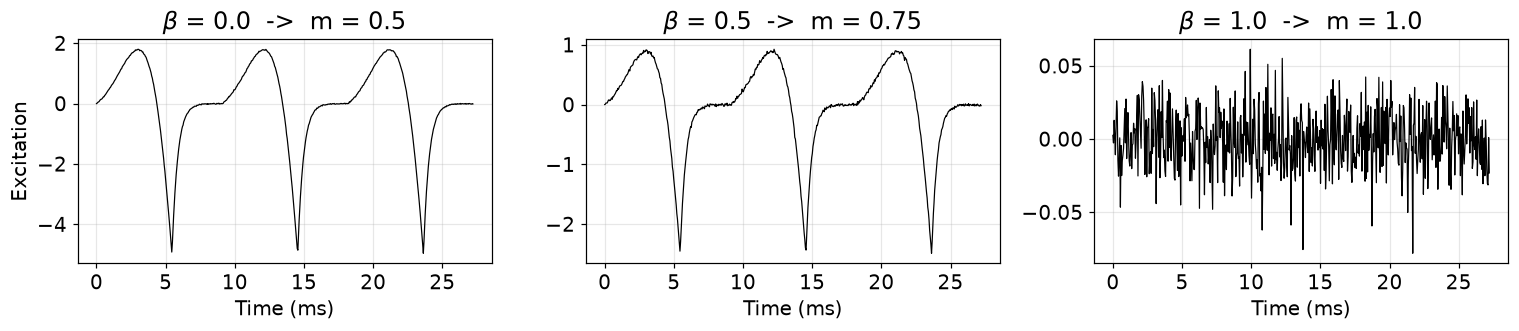

In [18]:
rng = np.random.default_rng(0)
g = v_glotlf(1, np.arange(int(3 * FS / F0_AVG)) * F0_AVG / FS)   # three LF periods
nu = 0.2 * rng.normal(0, 0.1, len(g))                             # same noise level as convert()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.2))                  # own y-scale each: the noise is tiny
for ax, b in zip(axs, (0.0, 0.5, 1.0)):
    m = 0.5 * b + 0.5
    ax.plot(np.arange(len(g)) / FS * 1e3, (1 - m) * g + m * nu, color='k', lw=0.8)
    ax.set(title=f'$\\beta$ = {b}  ->  m = {m}', xlabel='Time (ms)')
axs[0].set_ylabel('Excitation')
plt.tight_layout()
plt.show()

## 5 · Complete system (Ch. 6.4, 7)

Everything together: per-pulse filtering, plus WAD, centre-of-gravity voicing, and the $F_0$ contour restarting at each voiced onset. These are the stimuli of the MUSHRA whisper-to-speech test:

| Condition | What it is |
|---|---|
| Whispered | the input |
| Frame filtering | one filter per block, constant $\hat F_0$ (electrolarynx-like) |
| Pulse filtering | per-pulse interpolated filters, constant $\hat F_0$ |
| Complete system | pulse filtering + WAD + V/UV mixing + $F_0$ contour |

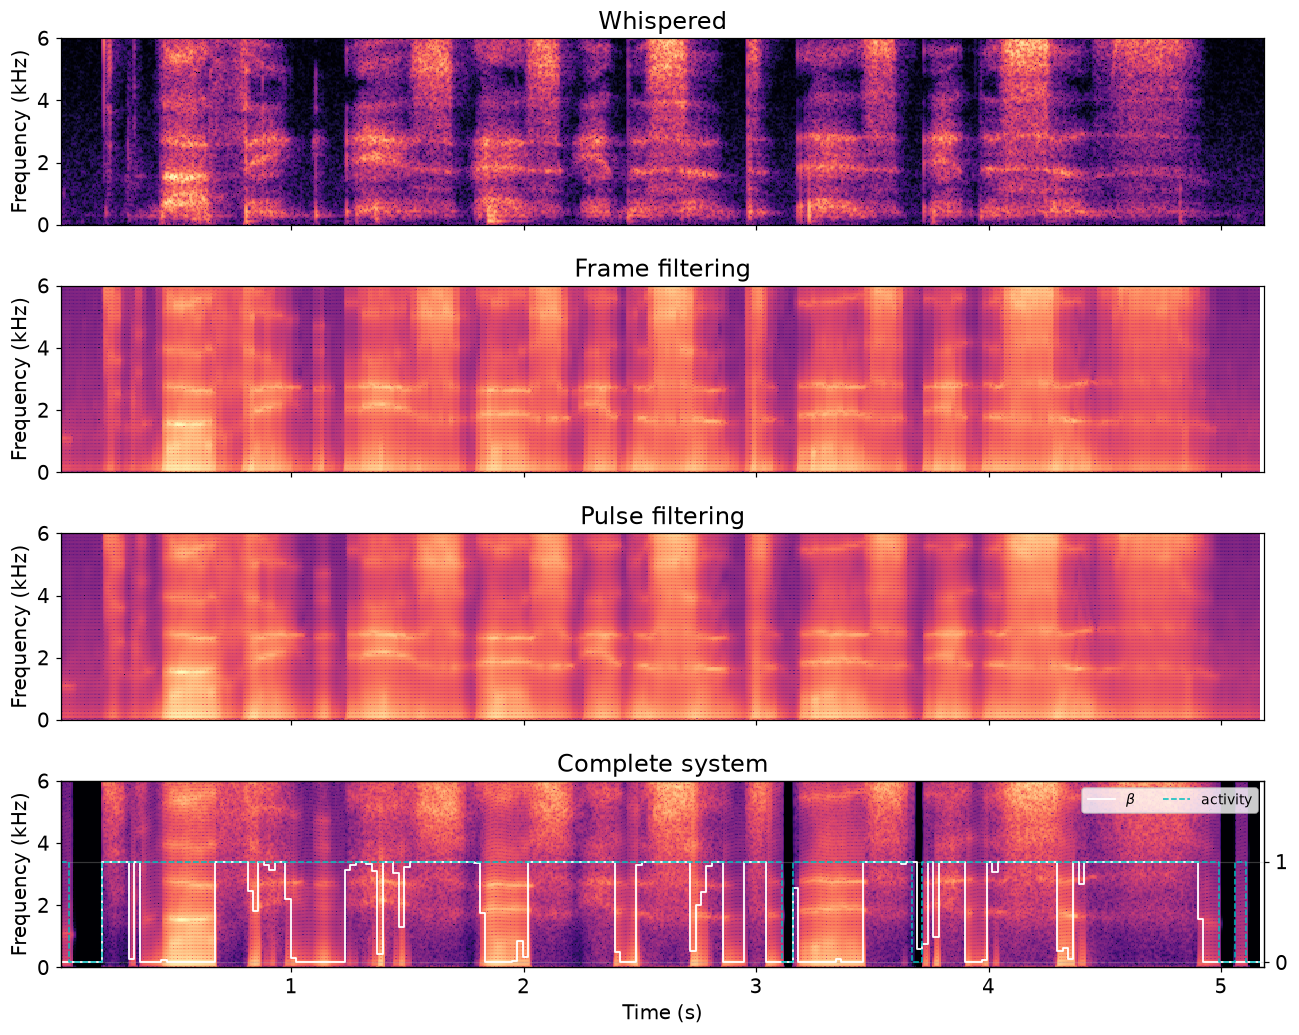

Whispered


Frame filtering


Pulse filtering


Complete system


In [19]:
# legacy_output_window=True reproduces how the frame/pulse filtering stimuli were rendered (overlapAdd.ipynb);
# the complete-system stimuli (SegmentationF0.ipynb) were rendered without it.
CONDITIONS = {
    'Frame filtering': dict(mode='frame', legacy_output_window=False),
    'Pulse filtering': dict(mode='pulse', legacy_output_window=False),
    'Complete system': dict(mode='pulse', segmentation=True, contour=True),
}

outputs = {'Whispered': whisper}
traces = {}
for name, kw in CONDITIONS.items():
    outputs[name], traces[name] = convert(whisper, **kw)

fig, axs = plt.subplots(len(outputs), 1, figsize=(12, 2.4 * len(outputs)), sharex=True)
for ax, (name, synth_voice) in zip(axs, outputs.items()):
    specshow(ax, synth_voice, fmax=6000)
    ax.set(title=name, xlabel='')

tr = traces['Complete system']
ax_v = axs[-1].twinx()
ax_v.step(t_blk, tr['beta'], where='mid', color='w', lw=1.2, label=r'$\beta$')
ax_v.step(t_blk, tr['activity'], where='mid', color='c', lw=1.0, ls='--', label='activity')
ax_v.set(ylim=(-0.05, 1.8), yticks=[0, 1])
ax_v.legend(fontsize=9, loc='upper right', ncol=2)
axs[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

for name, synth_voice in outputs.items():
    play(synth_voice, label=name)